# Oil Price Regression Analysis (OLS & Lasso)
Modeling monthly WTI crude oil prices (`oil`) using US Crude Oil Inventories (`Inventories`, `Inventories2`), Global Manufacturing PMI (`PMI`, `PMI2`), and the US Dollar Index (`DXY`, `DXY2`) from 2015 to 2025.

In [1]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.metrics import mean_squared_error
import warnings

sns.set()
warnings.filterwarnings('ignore')

In [2]:
# 2. Load the 2015–2025 dataset
rand_state = 1000
df = pd.read_csv('oil_inventories_pmi_dxy_2015_2025.csv')

# Separate target variable (y) and independent predictors (X)
y = df["oil"]
X = df.drop(["oil", "date"], axis=1)  # Keeps Inventories, Inventories2, PMI, PMI2, DXY, DXY2
X.head()

,Inventories,Inventories2,PMI,PMI2,DXY,DXY2
0,406.38,165144.70,49.76,2476.06,96.01,9217.92
1,422.84,178793.67,49.79,2479.04,97.35,9477.02
2,437.78,191651.33,50.85,2585.72,98.20,9643.24
3,447.62,200363.66,50.07,2507.00,95.54,9127.89
4,447.71,200444.24,50.52,2552.27,97.90,9584.41


In [3]:
# 3. Split data BEFORE scaling to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=rand_state
)

# 4. Standardize features and target (fit ONLY on training data)
scaler_X = StandardScaler()
X_train_sc = pd.DataFrame(
    scaler_X.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index
)
X_test_sc = pd.DataFrame(
    scaler_X.transform(X_test),
    columns=X.columns,
    index=X_test.index
)

scaler_y = StandardScaler()
y_train_sc = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_sc = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

In [4]:
# 5. Find optimal alpha for Lasso using 5-fold Cross-Validation
lassocv = LassoCV(cv=5, random_state=rand_state)
lassocv.fit(X_train_sc, y_train_sc)
alpha_lasso_opt = lassocv.alpha_
print(f"Optimal Lasso Alpha: {alpha_lasso_opt:.5f}")

# 6. Train OLS Linear Regression & Tuned Lasso
model_linear = LinearRegression()
model_lasso = Lasso(alpha=alpha_lasso_opt)

y_hat_linear = model_linear.fit(X_train_sc, y_train_sc).predict(X_test_sc)
y_hat_lasso = model_lasso.fit(X_train_sc, y_train_sc).predict(X_test_sc)

df_predictions = pd.DataFrame({
    'y_test_sc': y_test_sc,
    'y_hat_linear_sc': y_hat_linear,
    'y_hat_lasso_sc': y_hat_lasso
}, index=y_test.index)
df_predictions.head()

Optimal Lasso Alpha: 0.00045


,y_test_sc,y_hat_linear_sc,y_hat_lasso_sc
102,-0.329776,-0.062425,-0.139032
118,0.409331,0.292496,0.251260
68,-0.572659,-0.105218,-0.340088
44,1.456400,1.801967,1.619911
107,1.097305,0.692324,0.519281


In [5]:
# 7. Compare Coefficients
coefficients = pd.DataFrame({
    'Features': X.columns,
    'model_lin': model_linear.coef_,
    'model_lasso': model_lasso.coef_,
})
coefficients

,Features,model_lin,model_lasso
0,Inventories,-9.381493,-5.980269
1,Inventories2,8.278454,4.884101
2,PMI,-0.113112,0.574471
3,PMI2,0.723836,0.000000
4,DXY,2.173447,0.330709
5,DXY2,-2.715578,-0.898840


In [6]:
# 8. Evaluate Performance (Print BOTH standardized and $/barrel RMSE)
rmse_linear_sc = np.sqrt(mean_squared_error(y_test_sc, y_hat_linear))
rmse_lasso_sc = np.sqrt(mean_squared_error(y_test_sc, y_hat_lasso))

# Inverse-transform predictions back to actual $/barrel prices
y_hat_linear_dollars = scaler_y.inverse_transform(y_hat_linear.reshape(-1, 1)).ravel()
y_hat_lasso_dollars = scaler_y.inverse_transform(y_hat_lasso.reshape(-1, 1)).ravel()

rmse_linear_dollars = np.sqrt(mean_squared_error(y_test, y_hat_linear_dollars))
rmse_lasso_dollars = np.sqrt(mean_squared_error(y_test, y_hat_lasso_dollars))

print(f"Test RMSE (Standardized) - OLS: {rmse_linear_sc:.3f} | Lasso: {rmse_lasso_sc:.3f}")
print(f"Test RMSE ($/barrel)     - OLS: ${rmse_linear_dollars:.2f} | Lasso: ${rmse_lasso_dollars:.2f}")

Test RMSE (Standardized) - OLS: 0.603 | Lasso: 0.537
Test RMSE ($/barrel)     - OLS: $5.19 | Lasso: $4.62


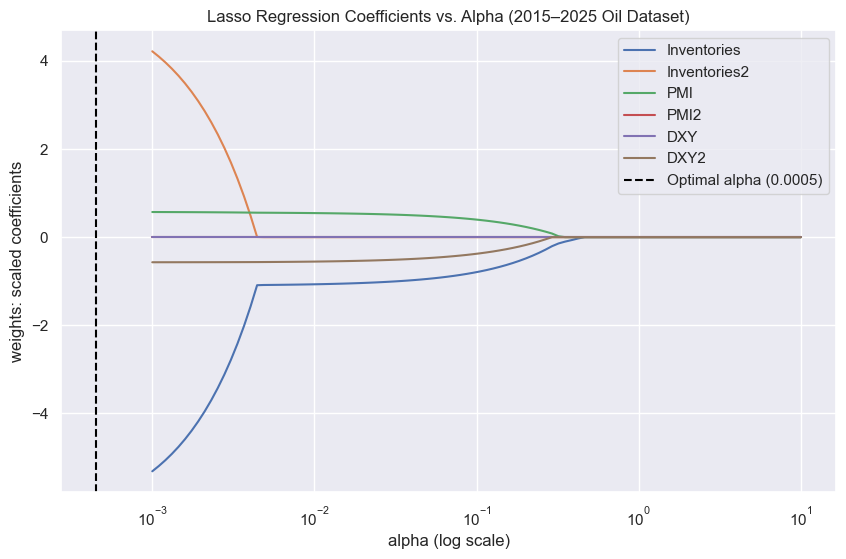

In [7]:
# 9. Plot Lasso Coefficient Path across Alphas
alpha_lasso = 10**np.linspace(-3, 1, 100)
coefs_lasso = []

for a in alpha_lasso:
    lasso_temp = Lasso(alpha=a)
    lasso_temp.fit(X_train_sc, y_train_sc)
    coefs_lasso.append(lasso_temp.coef_)

plt.figure(figsize=(10, 6))
ax = plt.gca()
ax.plot(alpha_lasso, coefs_lasso)
ax.axvline(alpha_lasso_opt, color='black', linestyle='--', label=f'Optimal alpha ({alpha_lasso_opt:.4f})')
ax.set_xscale('log')
plt.xlabel('alpha (log scale)')
plt.ylabel('weights: scaled coefficients')
plt.title('Lasso Regression Coefficients vs. Alpha (2015–2025 Oil Dataset)')
plt.legend(list(X.columns) + [f'Optimal alpha ({alpha_lasso_opt:.4f})'])
plt.show()